# Otimização de rotas de entrega: Caixeiro Viajante (TSP) + 2-Opt
**Pesquisa Operacional I | A2, Etapa 2 | Trilha 5**

Dados: *Amazon Last Mile Routing Research Challenge* (13 rotas reais de 2018, CC BY-NC 4.0). O notebook baixa os dados sozinho se a pasta `dados/amazon` não existir.

**Pergunta:** dada a lista de entregas de um veículo, em que ordem visitá-las para gastar menos, e quanto isso melhora a rota que o motorista fez?

No Colab: *Ambiente de execução → Executar tudo*.

In [1]:
import itertools, json, time, urllib.request
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import coo_matrix, csr_matrix, vstack
from scipy.sparse.csgraph import connected_components, maximum_flow

RAIZ = Path.cwd()
PASTA, SAIDA = RAIZ / "dados" / "amazon", RAIZ / "resultados"
SAIDA.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://amazon-last-mile-challenges.s3.amazonaws.com/almrrc2021/almrrc2021-data-training/"
ARQUIVOS = {
    "new_route_data.json": "model_apply_inputs/",
    "new_travel_times.json": "model_apply_inputs/",
    "new_package_data.json": "model_apply_inputs/",
    "new_actual_sequences.json": "model_score_inputs/",
}
RAIO_TERRA_KM = 6371.0

# PREMISSAS (hipoteses do grupo, nao vem da Amazon): edite aqui
CUSTO_HORA = 30.0    # R$ por hora de motorista
CUSTO_KM = 1.20      # R$ por km (combustivel + manutencao)
DIAS_ANO = 300       # dias de operacao por ano

ANTES, DEPOIS, TINTA = "#8a8983", "#2a78d6", "#33322e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "text.color": TINTA, "axes.titlesize": 11})

## 1. Dados: carga, limpeza e validação

In [2]:
def ler_json(nome: str) -> dict:
    """Le o arquivo local; se nao existir, baixa do bucket publico da Amazon."""
    arq = PASTA / nome
    if not arq.exists():
        PASTA.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + ARQUIVOS[nome] + nome, arq)
    with open(arq, encoding="utf-8") as f:
        return json.load(f)


def haversine(coords: np.ndarray) -> np.ndarray:
    """Matriz simetrica de distancias em km a partir de (lat, lng) em graus."""
    lat, lon = np.radians(coords[:, 0]), np.radians(coords[:, 1])
    dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
    a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
    return 2 * RAIO_TERRA_KM * np.arcsin(np.sqrt(a))


def carregar_rotas() -> list[dict]:
    """Monta, para cada rota, a instancia de TSP: nos, matrizes e rota real.

    O no 0 e sempre o deposito. Faz as validacoes de limpeza da base.
    """
    rotas, tempos, pacotes, seqs = (ler_json(n) for n in ARQUIVOS)
    instancias = []
    for rid, info in rotas.items():
        paradas = info["stops"]
        deposito = [p for p, d in paradas.items() if d["type"] == "Station"]
        assert len(deposito) == 1, f"{rid}: esperava 1 deposito"
        ids = deposito + sorted(p for p in paradas if p != deposito[0])
        n = len(ids)

        coords = np.array([[paradas[p]["lat"], paradas[p]["lng"]] for p in ids])
        assert not np.isnan(coords).any(), f"{rid}: parada sem coordenada"

        T = np.array([[tempos[rid][a][b] for b in ids] for a in ids], dtype=float)
        assert T.shape == (n, n) and not np.isnan(T).any() and (T >= 0).all()
        np.fill_diagonal(T, 0.0)

        ordem = seqs[rid]["actual"]  # parada -> posicao na rota real
        assert sorted(ordem.values()) == list(range(n)) and ordem[ids[0]] == 0
        pos = {p: i for i, p in enumerate(ids)}
        rota_real = [pos[p] for p in sorted(ordem, key=ordem.get)]

        servico = np.array([sum(x["planned_service_time_seconds"] for x in pacotes[rid].get(p, {}).values())
                            for p in ids])
        partida = datetime.fromisoformat(f'{info["date_YYYY_MM_DD"]}T{info["departure_time_utc"]}')
        seg = lambda s: (datetime.fromisoformat(s) - partida).total_seconds()
        janelas = [(pos[p], seg(x["time_window"]["start_time_utc"]), seg(x["time_window"]["end_time_utc"]))
                   for p in ids for x in pacotes[rid].get(p, {}).values()
                   if isinstance(x["time_window"]["start_time_utc"], str)]
        pk = [x for parada in pacotes[rid].values() for x in parada.values()]
        com_janela = sum(1 for x in pk if x["time_window"]["start_time_utc"] == x["time_window"]["start_time_utc"])

        instancias.append({
            "id": rid, "estacao": info["station_code"], "data": info["date_YYYY_MM_DD"],
            "ids": ids, "coords": coords, "T": T, "D": haversine(coords),
            "rota_real": rota_real, "pacotes": len(pk), "pacotes_com_janela": com_janela,
            "servico": servico, "janelas": janelas,
        })
    return instancias


instancias = carregar_rotas()
pd.DataFrame([{"rota": k, "estacao": i["estacao"], "data": i["data"], "paradas": len(i["ids"]) - 1,
               "pacotes": i["pacotes"], "com_janela": i["pacotes_com_janela"],
               "assimetria_max_s": abs(i["T"] - i["T"].T).max()} for k, i in enumerate(instancias)])

,rota,estacao,data,paradas,pacotes,com_janela,assimetria_max_s
0,0,DCH4,2018-08-11,192,287,1,223.0
1,1,DLA7,2018-07-22,165,238,1,143.6
2,2,DLA7,2018-07-22,150,228,3,206.0
3,3,DSE5,2018-08-25,167,237,10,131.0
4,4,DBO2,2018-08-15,181,253,17,351.1
5,5,DSE4,2018-08-21,186,283,10,172.3
6,6,DLA8,2018-08-09,139,205,21,344.5
7,7,DLA7,2018-07-31,139,212,34,254.6
8,8,DBO2,2018-08-08,153,250,12,246.9
9,9,DSE4,2018-07-25,104,229,20,263.9


## 2. Modelo
$$\min Z=\sum_{i\ne j}c_{ij}x_{ij}$$
sujeito a $\sum_j x_{ij}=1\ \forall i$; $\sum_i x_{ij}=1\ \forall j$; $u_i-u_j+(n-1)x_{ij}\le n-2$ para $i\ne j\in\{1..n-1\}$; $x_{ij}\in\{0,1\}$; $1\le u_i\le n-1$.

Nó 0 = depósito. $c_{ij}$ é o tempo (s), a distância em linha reta Haversine (km) ou o custo (R\$).

## 3. Algoritmos
Vizinho Mais Próximo (constrói) e 2-Opt (melhora). O 2-Opt troca $(a\to b),(c\to d)$ por $(a\to c),(b\to d)$ e inverte $b..c$:
$$\Delta=c_{ac}+c_{bd}-c_{ab}-c_{cd}+[\text{trecho invertido}-\text{trecho}]$$

In [3]:
def custo_rota(rota: list[int], C: np.ndarray) -> float:
    """Z = soma dos custos c(i,j) dos arcos usados, incluindo a volta ao deposito."""
    r = np.asarray(rota)
    return float(C[r, np.roll(r, -1)].sum())


def vizinho_mais_proximo(C: np.ndarray, inicio: int = 0) -> list[int]:
    n = len(C)
    livre = np.ones(n, dtype=bool)
    livre[inicio] = False
    rota = [inicio]
    while len(rota) < n:
        linha = np.where(livre, C[rota[-1]], np.inf)
        prox = int(linha.argmin())
        rota.append(prox)
        livre[prox] = False
    return rota


def two_opt(rota: list[int], C: np.ndarray) -> tuple[list[int], list[dict]]:
    """Troca os arcos (a->b) e (c->d) por (a->c) e (b->d), invertendo o trecho b..c.

    Ganho do movimento:
        delta = c(a,c) + c(b,d) - c(a,b) - c(c,d) + [custo(trecho invertido) - custo(trecho)]
    Em matriz simetrica o termo entre colchetes e zero (2-Opt classico). Em matriz
    assimetrica (tempos de viagem reais) ele precisa entrar na conta, porque o
    trecho b..c passa a ser percorrido no sentido contrario. Somas acumuladas
    deixam cada avaliacao em O(1). O deposito (posicao 0) nunca sai do lugar.
    """
    r = np.array(rota)
    n = len(r)
    historico = [{"z": custo_rota(r, C)}]   # historico[k] = estado apos k movimentos
    while True:
        prox = np.roll(r, -1)
        ida = np.concatenate(([0.0], np.cumsum(C[r, prox])))      # ida[k]  = custo dos arcos 0..k-1
        volta = np.concatenate(([0.0], np.cumsum(C[prox, r])))    # mesmos arcos, sentido inverso
        melhor_delta, melhor_ij = -1e-9, None
        for i in range(n - 1):
            j = np.arange(i + 2, n)                                # trecho invertido: posicoes i+1..j
            if len(j) == 0:
                continue
            a, b, c, d = r[i], r[i + 1], r[j], r[(j + 1) % n]
            inversao = (volta[j] - volta[i + 1]) - (ida[j] - ida[i + 1])
            delta = C[a, c] + C[b, d] - C[a, b] - C[c, d] + inversao
            k = int(delta.argmin())
            if delta[k] < melhor_delta:
                melhor_delta, melhor_ij = float(delta[k]), (i, int(j[k]))
        if melhor_ij is None:
            return r.tolist(), historico
        i, j = melhor_ij
        r[i + 1 : j + 1] = r[i + 1 : j + 1][::-1].copy()
        historico.append({"z": historico[-1]["z"] + melhor_delta, "i": i, "j": j, "delta": melhor_delta})


def validar(rota, n):
    """Confere as restricoes do modelo na solucao final; falha se alguma for violada."""
    x = np.zeros((n, n), dtype=int)
    np.add.at(x, (rota, np.roll(rota, -1)), 1)
    assert len(rota) == n and rota[0] == 0, "nao comeca no deposito"
    assert (x.sum(axis=1) == 1).all(), "restricao 1 (sair uma vez)"
    assert (x.sum(axis=0) == 1).all(), "restricao 2 (chegar uma vez)"
    assert x.max() == 1 and np.trace(x) == 0, "dominio de x"
    u = np.empty(n, dtype=int)
    u[rota] = np.arange(n)
    mtz = u[1:, None] - u[None, 1:] + (n - 1) * x[1:, 1:]
    np.fill_diagonal(mtz, -n)
    assert (mtz <= n - 2).all(), "restricao 3 (MTZ, subciclo)"
    assert u[1:].min() >= 1 and u[1:].max() <= n - 1, "dominio de u"

## 4. Passo manual do 2-Opt com dados reais
O 1º movimento na rota DBO2 de 08/08/2018: primeiro em distância (simétrica, o termo extra é zero), depois em tempo (assimétrica).

DISTANCIA (km)
a=DB (pos 138)  b=YN (pos 139)  c=YI (pos 153)  d=DEPOSITO (pos 0)
  saem  : c(a,b) = 1.592   c(c,d) = 8.159
  entram: c(a,c) = 1.049   c(b,d) = 6.703
  trecho b..c: ida = 5.211   invertido = 5.211   diferenca = +0.000
  delta = -2.000 km
  Z: 44.352 -> 42.352 km

TEMPO (s)
a=TH (pos 87)  b=PY (pos 88)  c=DR (pos 115)  d=DO (pos 116)
  saem  : c(a,b) = 134.100   c(c,d) = 164.300
  entram: c(a,c) = 49.100   c(b,d) = 72.100
  trecho b..c: ida = 1784.500   invertido = 1726.200   diferenca = -58.300
  delta = -235.500 s
  Z: 12459.200 -> 12223.700 s



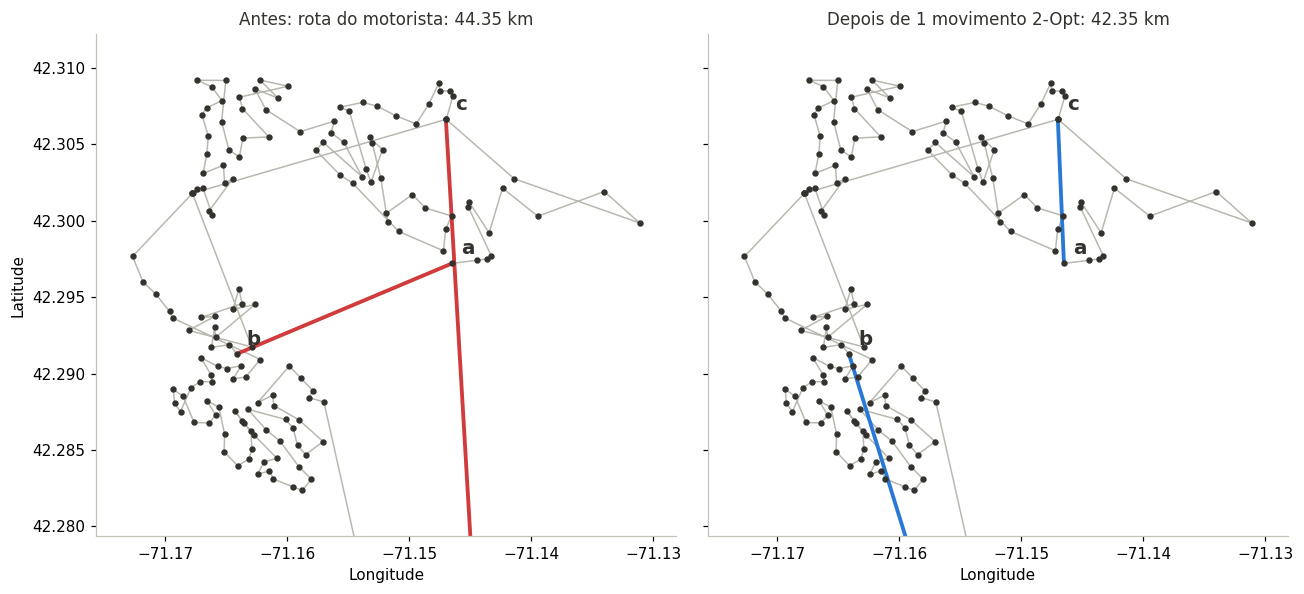

In [4]:
DEMO = next(k for k, i in enumerate(instancias) if (i["estacao"], i["data"]) == ("DBO2", "2018-08-08"))

def passo_manual(inst, C, un):
    r = inst["rota_real"]
    _, h = two_opt(r, C)
    i, j = h[1]["i"], h[1]["j"]
    a, b, c, d = r[i], r[i + 1], r[j], r[(j + 1) % len(r)]
    nome = lambda v: "DEPOSITO" if v == 0 else inst["ids"][v]
    trecho = r[i + 1:j + 1]
    ida = sum(C[p, q] for p, q in zip(trecho, trecho[1:]))
    volta = sum(C[q, p] for p, q in zip(trecho, trecho[1:]))
    print(f"a={nome(a)} (pos {i})  b={nome(b)} (pos {i+1})  c={nome(c)} (pos {j})  d={nome(d)} (pos {(j+1) % len(r)})")
    print(f"  saem  : c(a,b) = {C[a,b]:.3f}   c(c,d) = {C[c,d]:.3f}")
    print(f"  entram: c(a,c) = {C[a,c]:.3f}   c(b,d) = {C[b,d]:.3f}")
    print(f"  trecho b..c: ida = {ida:.3f}   invertido = {volta:.3f}   diferenca = {volta-ida:+.3f}")
    delta = C[a, c] + C[b, d] - C[a, b] - C[c, d] + (volta - ida)
    nova = r[:i + 1] + trecho[::-1] + r[j + 1:]
    print(f"  delta = {delta:.3f} {un}")
    print(f"  Z: {custo_rota(r, C):.3f} -> {custo_rota(nova, C):.3f} {un}\n")
    assert abs(delta - h[1]["delta"]) < 1e-6 and abs(custo_rota(nova, C) - custo_rota(r, C) - delta) < 1e-6
    return i, j, nova

inst = instancias[DEMO]
print("DISTANCIA (km)"); i, j, nova = passo_manual(inst, inst["D"], "km")
print("TEMPO (s)"); _ = passo_manual(inst, inst["T"], "s")

r, xy = inst["rota_real"], inst["coords"]
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, rota, tit, cor in [(eixos[0], r, "Antes: rota do motorista", "#d03b3b"), (eixos[1], nova, "Depois de 1 movimento 2-Opt", DEPOIS)]:
    ciclo = rota + [0]
    ax.plot(xy[ciclo, 1], xy[ciclo, 0], color="#b9b8b0", lw=1)
    for k in (i, j):   # os dois arcos trocados
        p, q = ciclo[k], ciclo[k + 1]
        ax.plot(xy[[p, q], 1], xy[[p, q], 0], color=cor, lw=2.5)
    ax.scatter(xy[1:, 1], xy[1:, 0], s=10, color=TINTA, zorder=3)
    for v, l in zip((r[i], r[i + 1], r[j], r[(j + 1) % len(r)]), "abcd"):
        if v:
            ax.annotate(l, (xy[v, 1], xy[v, 0]), xytext=(6, 6), textcoords="offset points", fontsize=13, weight="bold")
    ax.set_title(f"{tit}: {custo_rota(rota, inst['D']):.2f} km"); ax.set_xlabel("Longitude")
m_ = 0.003
eixos[0].set(xlim=(xy[1:, 1].min() - m_, xy[1:, 1].max() + m_), ylim=(xy[1:, 0].min() - m_, xy[1:, 0].max() + m_), ylabel="Latitude")
fig.tight_layout(); fig.savefig(SAIDA / "passo_manual.png", dpi=130); plt.show()

## 5. Execução nas 13 rotas, com validação das restrições
Cada métrica é uma otimização separada. Em `custo`, a matriz combina tempo e distância usando as premissas.

In [5]:
def matriz_custo(inst, hora=CUSTO_HORA, km=CUSTO_KM):
    return hora * inst["T"] / 3600 + km * inst["D"]

def resolver(inst, C):
    """Roda os 4 metodos, valida cada rota e devolve a melhor."""
    n, t0 = len(C), time.perf_counter()
    real, vmp = inst["rota_real"], vizinho_mais_proximo(C)
    r2, h_r = two_opt(real, C)
    v2, h_v = two_opt(vmp, C)
    seg = time.perf_counter() - t0
    rotas = {"real": real, "vmp": vmp, "real+2opt": r2, "vmp+2opt": v2}
    for rota in rotas.values():
        validar(rota, n)
    z = {k: custo_rota(v, C) for k, v in rotas.items()}
    melhor = min(("real+2opt", "vmp+2opt"), key=z.get)
    return {"rotas": rotas, "z": z, "melhor": rotas[melhor], "z_melhor": z[melhor],
            "hist": {"Rota real + 2-Opt": h_r, "VMP + 2-Opt": h_v}, "seg": seg}

METRICAS = {"tempo (h)": lambda i: i["T"] / 3600, "distancia (km)": lambda i: i["D"], "custo (R$)": matriz_custo}
sol = {m: [resolver(i, f(i)) for i in instancias] for m, f in METRICAS.items()}
tab = pd.DataFrame([{"metrica": m, "rota": f'{i["estacao"]} {i["data"]}', "paradas": len(i["ids"]) - 1, **s["z"],
                     "melhor": s["z_melhor"], "seg": s["seg"]}
                    for m in METRICAS for i, s in zip(instancias, sol[m])])
tab["reducao_%"] = 100 * (1 - tab["melhor"] / tab["real"])
tot = tab.groupby("metrica", sort=False)[["real", "vmp", "real+2opt", "vmp+2opt", "melhor", "seg"]].sum()
tot["reducao_%"] = 100 * (1 - tot["melhor"] / tot["real"])
print(f"{sum(len(s['rotas']) for m in sol for s in sol[m])} rotas passaram em todas as restricoes")
tot.round(2)

156 rotas passaram em todas as restricoes


,real,vmp,real+2opt,vmp+2opt,melhor,seg,reducao_%
metrica,,,,,,,
tempo (h),49.39,51.24,46.19,48.32,46.10,1.46,6.66
distancia (km),870.81,829.80,755.00,748.55,746.32,2.62,14.30
custo (R$),2526.71,2586.78,2375.93,2421.70,2370.75,1.86,6.17


## 6. Quão perto do ótimo?
O 2-Opt garante ótimo **local**, não global. Medimos de duas formas:
1. **Held-Karp** (exato) em 12 nós;
2. **limite inferior** nas rotas completas: relaxação linear do TSP com cortes de subciclo. Nenhuma rota custa menos que esse valor, logo a distância ao ótimo é **no máximo** o gap mostrado.

In [6]:
def held_karp(C: np.ndarray) -> float:
    n = len(C)
    tab = {(1 << k, k): C[0, k] for k in range(1, n)}
    for tam in range(2, n):
        for sub in itertools.combinations(range(1, n), tam):
            bits = sum(1 << b for b in sub)
            for k in sub:
                ant = bits & ~(1 << k)
                tab[(bits, k)] = min(tab[(ant, m)] + C[m, k] for m in sub if m != k)
    tudo = (1 << n) - 2
    return float(min(tab[(tudo, k)] + C[k, 0] for k in range(1, n)))


def limite_inferior(C):
    """Relaxacao linear (0<=x<=1) + cortes de subciclo achados por corte minimo."""
    n = len(C)
    I, J = np.where(~np.eye(n, dtype=bool))
    k, um = np.arange(len(I)), np.ones(len(I))
    Aeq = vstack([coo_matrix((um, (I, k)), (n, len(I))), coo_matrix((um, (J, k)), (n, len(I)))]).tocsr()
    cortes = []
    while True:
        res = linprog(C[I, J], A_ub=vstack(cortes).tocsr() if cortes else None, b_ub=-np.ones(len(cortes)) if cortes else None,
                      A_eq=Aeq, b_eq=np.ones(2 * n), bounds=(0, 1), method="highs")
        assert res.status == 0
        cap = csr_matrix((np.round(res.x * 1e6).astype(np.int32), (I, J)), (n, n)); cap.eliminate_zeros()
        nc, rot = connected_components(cap, directed=False)
        conjuntos = {frozenset(np.where(rot == q)[0].tolist()) for q in range(nc)} if nc > 1 else set()
        if nc == 1:
            for t in range(1, n):
                f = maximum_flow(cap, 0, t)
                if f.flow_value < 1e6 - 1e3:      # menos de 1 unidade do deposito ate t: corte violado
                    resid = (cap - f.flow).tocsr(); resid.eliminate_zeros()
                    alc, pilha = {0}, [0]         # nos alcancaveis na rede residual
                    while pilha:
                        v = pilha.pop()
                        for w in resid.indices[resid.indptr[v]:resid.indptr[v + 1]].tolist():
                            if w not in alc:
                                alc.add(w); pilha.append(w)
                    conjuntos.add(frozenset(alc))
        if not conjuntos or len(cortes) > 3000:   # parar antes ainda da um limite valido
            return float(res.fun)
        for S in conjuntos:      # pelo menos um arco deve sair de S
            dentro = np.zeros(n, dtype=bool); dentro[list(S)] = True
            cortes.append(csr_matrix(-(dentro[I] & ~dentro[J]).astype(float)))

sub = instancias[0]["rota_real"][:12]
for m in ("tempo (h)", "distancia (km)"):
    C = METRICAS[m](instancias[0])[np.ix_(sub, sub)]
    otimo, heur = held_karp(C), custo_rota(two_opt(vizinho_mais_proximo(C), C)[0], C)
    print(f"Held-Karp 12 nos, {m}: otimo {otimo:.3f} | 2-Opt {heur:.3f} | gap {100*(heur/otimo-1):.2f}%")

t0 = time.perf_counter()
for m in ("tempo (h)", "distancia (km)"):
    tab.loc[tab.metrica == m, "limite"] = [limite_inferior(METRICAS[m](i)) for i in instancias]
tab["gap_max_%"] = 100 * (tab["melhor"] / tab["limite"] - 1)
tab["gap_motorista_%"] = 100 * (tab["real"] / tab["limite"] - 1)
tab.to_csv(SAIDA / "resultados_finais.csv", index=False)
print(f"limites calculados em {time.perf_counter()-t0:.0f} s")
g = tab.dropna().groupby("metrica", sort=False)
resumo = g[["real", "melhor", "limite"]].sum()
resumo["gap_2opt_%"] = 100 * (resumo.melhor / resumo.limite - 1)
resumo["gap_motorista_%"] = 100 * (resumo.real / resumo.limite - 1)
resumo["pior_gap_2opt_%"] = g["gap_max_%"].max()
assert (tab.dropna().melhor >= tab.dropna().limite - 1e-6).all()
resumo.round(2)

Held-Karp 12 nos, tempo (h): otimo 1.218 | 2-Opt 1.218 | gap 0.00%
Held-Karp 12 nos, distancia (km): otimo 34.356 | 2-Opt 34.458 | gap 0.30%


limites calculados em 100 s


,real,melhor,limite,gap_2opt_%,gap_motorista_%,pior_gap_2opt_%
metrica,,,,,,
tempo (h),49.39,46.10,43.14,6.86,14.49,20.59
distancia (km),870.81,746.32,731.55,2.02,19.04,4.33


## 7. Painel executivo: antes × depois

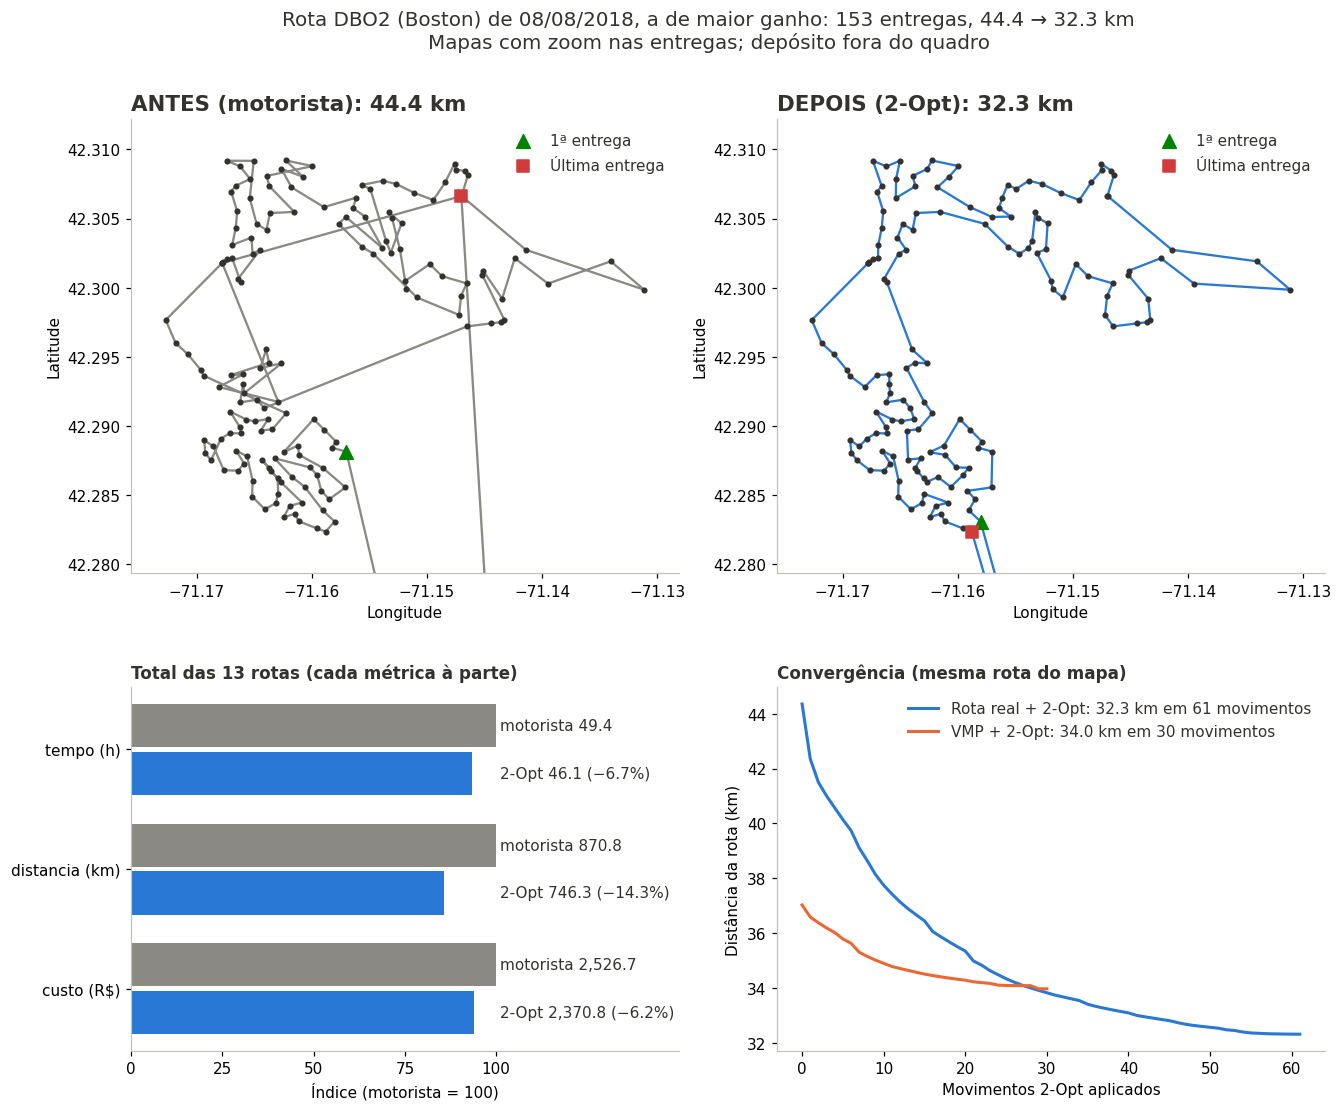

In [7]:
s, D = sol["distancia (km)"][DEMO], inst["D"]
fig = plt.figure(figsize=(14, 11)); gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1], hspace=.28, wspace=.18)
eixo = None
for col, (tit, rota, cor) in enumerate([("ANTES (motorista)", s["rotas"]["real"], ANTES), ("DEPOIS (2-Opt)", s["melhor"], DEPOIS)]):
    ax = fig.add_subplot(gs[0, col], sharex=eixo, sharey=eixo); eixo = eixo or ax
    ciclo = rota + [0]
    ax.plot(xy[ciclo, 1], xy[ciclo, 0], color=cor, lw=1.5)
    ax.scatter(xy[1:, 1], xy[1:, 0], s=9, color=TINTA, zorder=3)
    ax.scatter(xy[rota[1], 1], xy[rota[1], 0], s=80, marker="^", color="#008300", zorder=4, label="1ª entrega")
    ax.scatter(xy[rota[-1], 1], xy[rota[-1], 0], s=70, marker="s", color="#d03b3b", zorder=4, label="Última entrega")
    ax.set_title(f"{tit}: {custo_rota(rota, D):.1f} km", fontsize=14, weight="bold", loc="left"); ax.legend(frameon=False)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
eixo.set(xlim=(xy[1:, 1].min() - m_, xy[1:, 1].max() + m_), ylim=(xy[1:, 0].min() - m_, xy[1:, 0].max() + m_))

ax = fig.add_subplot(gs[1, 0]); b = np.arange(3)
ax.barh(b, [100] * 3, .36, color=ANTES); ax.barh(b + .4, 100 - tot["reducao_%"], .36, color=DEPOIS)
for k, nome in enumerate(METRICAS):
    ax.text(101, k, f"motorista {tot['real'][nome]:,.1f}", va="center")
    ax.text(101, k + .4, f"2-Opt {tot['melhor'][nome]:,.1f} (−{tot['reducao_%'][nome]:.1f}%)", va="center")
ax.set_yticks(b + .2, [x.replace("$", r"\$") for x in METRICAS]); ax.invert_yaxis(); ax.set_xlim(0, 150); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Índice (motorista = 100)"); ax.set_title("Total das 13 rotas (cada métrica à parte)", loc="left", weight="bold")

ax = fig.add_subplot(gs[1, 1])
for (nome, h), cor in zip(s["hist"].items(), (DEPOIS, "#eb6834")):
    ax.plot([q["z"] for q in h], lw=2, color=cor, label=f"{nome}: {h[-1]['z']:.1f} km em {len(h)-1} movimentos")
ax.legend(frameon=False)
ax.set(xlabel="Movimentos 2-Opt aplicados", ylabel="Distância da rota (km)")
ax.set_title("Convergência (mesma rota do mapa)", loc="left", weight="bold")
fig.suptitle(f"Rota DBO2 (Boston) de 08/08/2018, a de maior ganho: {len(xy)-1} entregas, {s['z']['real']:.1f} → {s['z_melhor']:.1f} km\n"
             "Mapas com zoom nas entregas; depósito fora do quadro", fontsize=13, y=.97)
fig.savefig(SAIDA / "painel_executivo.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Análise de tempo de execução

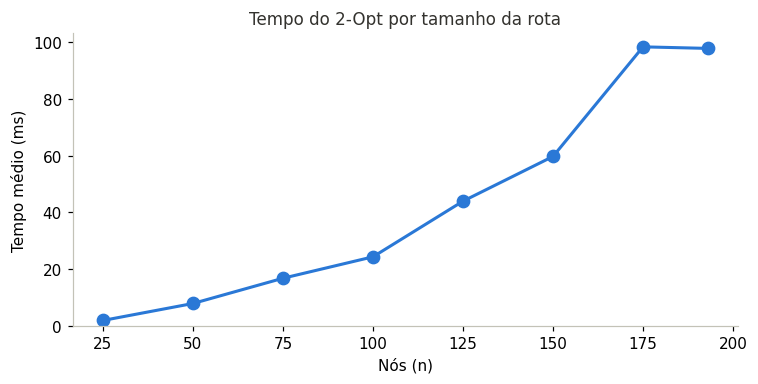

tempo cresce como n^2.0 nesta faixa | 13 rotas x 3 metricas: 5.9 s


,n,segundos,movimentos
0,25,0.0018,5.0
1,50,0.0078,8.4
2,75,0.0167,13.8
3,100,0.0243,15.0
4,125,0.0439,24.6
5,150,0.0597,24.2
6,175,0.0983,30.8
7,193,0.0978,26.2


In [8]:
rng = np.random.default_rng(42)
tempos_exec, C0 = [], instancias[0]["T"]
for n in (25, 50, 75, 100, 125, 150, 175, 193):
    reps = []
    for _ in range(5):
        nos = np.r_[0, rng.choice(np.arange(1, len(C0)), n - 1, replace=False)]
        C = C0[np.ix_(nos, nos)]; ini = vizinho_mais_proximo(C)
        t0 = time.perf_counter(); _, h = two_opt(ini, C); reps.append((time.perf_counter() - t0, len(h) - 1))
    tempos_exec.append((n, *np.mean(reps, axis=0)))
te = pd.DataFrame(tempos_exec, columns=["n", "segundos", "movimentos"])
expo = np.polyfit(np.log(te.n), np.log(te.segundos), 1)[0]
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.plot(te.n, te.segundos * 1000, "o-", lw=2, ms=8, color=DEPOIS)
ax.set(xlabel="Nós (n)", ylabel="Tempo médio (ms)", title="Tempo do 2-Opt por tamanho da rota", ylim=(0, None))
fig.tight_layout(); fig.savefig(SAIDA / "tempo_execucao.png", dpi=130); plt.show()
print(f"tempo cresce como n^{expo:.1f} nesta faixa | 13 rotas x 3 metricas: {tot.seg.sum():.1f} s")
te.round(4)

## 9. Impacto financeiro e sensibilidade
As tarifas são **hipóteses editáveis**. Tempo e km abaixo são da **mesma** rota (a otimizada em R\$), para não somar ganhos de rotas diferentes. Km em linha reta, portanto menor que o rodado nas ruas. A anualização supõe que estas 13 rotas representam um dia típico: é um cenário, não uma previsão.

In [9]:
sc = sol["custo (R$)"]
def soma(chave, real):
    return sum(custo_rota(s["rotas"]["real"] if real else s["melhor"], i[chave]) for i, s in zip(instancias, sc))
h0, h1 = soma("T", True) / 3600, soma("T", False) / 3600
k0, k1 = soma("D", True), soma("D", False)
r0, r1 = tot["real"]["custo (R$)"], tot["melhor"]["custo (R$)"]
assert abs(CUSTO_HORA * (h0 - h1) + CUSTO_KM * (k0 - k1) - (r0 - r1)) < 1e-6
print(f"Tempo  {h0:.2f} -> {h1:.2f} h  (-{100*(1-h1/h0):.1f}%)\nKm     {k0:.1f} -> {k1:.1f} km (-{100*(1-k1/k0):.1f}%)")
print(f"Custo  R$ {r0:,.2f} -> R$ {r1:,.2f}  (-{100*(1-r1/r0):.1f}%, R$ {r0-r1:,.2f}/dia, R$ {(r0-r1)/13:,.2f} por rota)")
print(f"Cenario anual ({DIAS_ANO} dias, 13 veiculos): R$ {(r0-r1)*DIAS_ANO:,.0f}")

# Sensibilidade 1: reotimiza com outras tarifas
def reducao(hora, km):
    p = [resolver(i, matriz_custo(i, hora, km)) for i in instancias]
    return 100 * (1 - sum(q["z_melhor"] for q in p) / sum(q["z"]["real"] for q in p))
grade = pd.DataFrame({km: {hora: reducao(hora, km) for hora in (20, 30, 40)} for km in (0.80, 1.20, 1.80)})
grade.index.name, grade.columns.name = "R$/h", "R$/km"
print("\nReducao de custo (%) por tarifa:"); print(grade.round(1))

# Sensibilidade 2: transito. Rotas fixas; cada arco varia de forma independente (lognormal, media 1)
res = []
for cv in (.1, .2, .4):
    ganhos, sig = [], np.sqrt(np.log(1 + cv**2))
    for _ in range(200):
        a = b = 0
        for i, q in zip(instancias, sol["tempo (h)"]):
            N = i["T"] * rng.lognormal(-sig**2 / 2, sig, i["T"].shape)
            a += custo_rota(q["rotas"]["real"], N); b += custo_rota(q["melhor"], N)
        ganhos.append(100 * (1 - b / a))
    res.append({"variacao": f"{cv:.0%}", "ganho_medio_%": np.mean(ganhos), "p5_%": np.percentile(ganhos, 5),
                "p95_%": np.percentile(ganhos, 95), "cenarios_piores": int(sum(x < 0 for x in ganhos))})
pd.DataFrame(res).round(2)

Tempo  49.39 -> 46.24 h  (-6.4%)
Km     870.8 -> 819.7 km (-5.9%)
Custo  R$ 2,526.71 -> R$ 2,370.75  (-6.2%, R$ 155.96/dia, R$ 12.00 por rota)
Cenario anual (300 dias, 13 veiculos): R$ 46,788



Reducao de custo (%) por tarifa:
R$/km  0.8  1.2  1.8
R$/h                
20     6.2  6.8  8.1
30     6.0  6.2  6.8
40     6.2  6.2  6.3


,variacao,ganho_medio_%,p5_%,p95_%,cenarios_piores
0,10%,6.65,5.69,7.79,0
1,20%,6.87,4.99,8.80,0
2,40%,6.57,2.51,10.84,1


## 10. O que o modelo ignora: janelas de entrega
O TSP puro não conhece as janelas. Simulamos a chegada em cada parada (viagem + serviço planejado, saindo no horário da base) e contamos quantos pacotes com janela chegam até o fim do prazo. Não simulamos espera por chegada antecipada.

In [10]:
def no_prazo(inst, rota):
    t, cheg = 0.0, {}
    for p, q in zip(rota, rota[1:]):
        t += inst["T"][p, q]; cheg[q] = t; t += inst["servico"][q]
    return sum(cheg[p] <= fim for p, _, fim in inst["janelas"])

n_j = sum(len(i["janelas"]) for i in instancias)
for nome, rs in [("Motorista", [i["rota_real"] for i in instancias]),
                 ("2-Opt (tempo)", [q["melhor"] for q in sol["tempo (h)"]]), ("2-Opt (custo)", [q["melhor"] for q in sc])]:
    k = sum(no_prazo(i, r_) for i, r_ in zip(instancias, rs))
    print(f"{nome:14s}: {k}/{n_j} dentro do prazo ({100*k/n_j:.1f}%)")

Motorista     : 208/210 dentro do prazo (99.0%)
2-Opt (tempo) : 203/210 dentro do prazo (96.7%)
2-Opt (custo) : 207/210 dentro do prazo (98.6%)


## 11. Conclusão
- **Decisão:** usar a sequência do 2-Opt como sugestão inicial da rota, conferindo as janelas antes de despachar.
- **Qualidade:** a seção 6 mostra o ganho sobre o motorista e a distância máxima que ainda resta até o ótimo.
- **Limites:** janelas de entrega, conhecimento local do motorista, trânsito por horário e distância em linha reta. O próximo passo é o TSP com janelas (TSPTW).